# Stage 1: OpenCV Image Preprocessing for Historical Spanish Manuscripts

Pipeline of this notebook: **load → grayscale → denoise → fix uneven lighting → CLAHE → deskew → thresholding comparison → cleanup → save**

The cleaned image is the input to Stage 2 (OCR/HTR) of the research pipeline.

**Before you start:** put one scanned page at `data/sample_images/sample.jpg` (or change `IMAGE_PATH` below).

## Step 0. Install the libraries

| Library | Purpose |
|---|---|
| `opencv-python` | image processing (all preprocessing steps) |
| `numpy` | image arrays and math |
| `matplotlib` | showing images inside the notebook |
| `pytesseract` (optional) | quick OCR check at the end; also needs the **Tesseract program** with Spanish data (`spa`) installed on your computer |

Run the next cell once, then restart the kernel if the imports fail.

In [3]:
%pip install -q opencv-python numpy matplotlib
# Optional, for the OCR check in Step 10:
# %pip install -q pytesseract

Note: you may need to restart the kernel to use updated packages.


In [12]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)

def show(images, titles=None, cols=3, size=5):
    """Display one or more images side by side."""
    if not isinstance(images, (list, tuple)):
        images = [images]
    rows = (len(images) + cols - 1) // cols
    plt.figure(figsize=(size * min(cols, len(images)), size * rows))
    for i, im in enumerate(images):
        plt.subplot(rows, cols, i + 1)
        if im.ndim == 2:
            plt.imshow(im, cmap="gray", vmin=0, vmax=255)
        else:
            plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        if titles:
            plt.title(titles[i])
        plt.axis("off")
    plt.tight_layout()
    plt.show()

OpenCV version: 5.0.0


## Step 1. Load the image
`cv2.imread` returns `None` if the path is wrong, so we check it. OpenCV loads color images as **BGR**, not RGB.

Image size (height, width, channels): (1168, 848, 3)


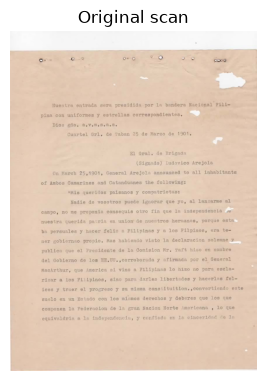

In [13]:
# Works whether Jupyter was started in the project folder or inside notebooks/
ROOT = "." if os.path.isdir("data") else ".."
IMAGE_PATH = os.path.join(ROOT, "data", "735771.png")

img = cv2.imread(IMAGE_PATH)
assert img is not None, f"Could not read {IMAGE_PATH}. Check the path."
print("Image size (height, width, channels):", img.shape)
show(img, ["Original scan"], size=8)

## Step 2. Convert to grayscale
Text recognition does not need color, and every later step works on a single channel.

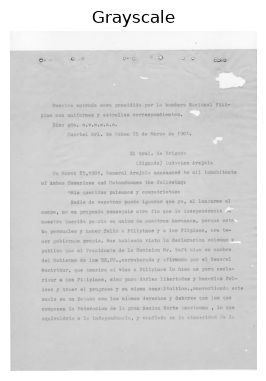

In [14]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
show(gray, ["Grayscale"], size=8)

## Step 3. Remove noise
Old scans have speckles and paper grain. Non-local means denoising removes noise while keeping stroke edges.
Raise `h` for noisier images, but too high will blur thin handwriting.

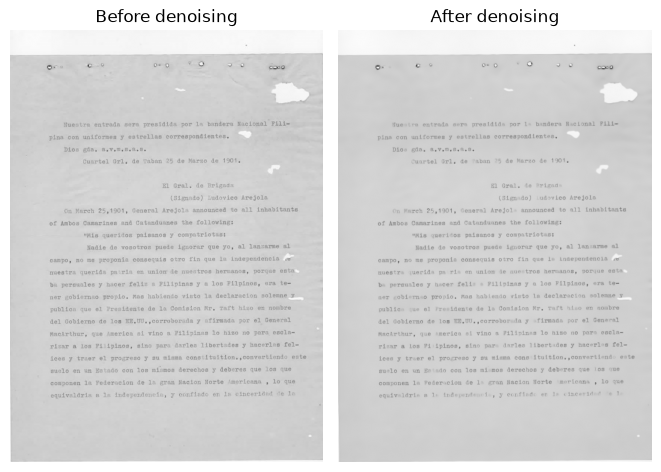

In [15]:
denoised = cv2.fastNlMeansDenoising(gray, None, h=10, templateWindowSize=7, searchWindowSize=21)
show([gray, denoised], ["Before denoising", "After denoising"])

## Step 4. Fix uneven lighting and stains
Estimate the paper background (dilate removes thin ink strokes, median blur smooths what is left),
then divide the image by it. This flattens shadows, yellowing and light bleed-through.

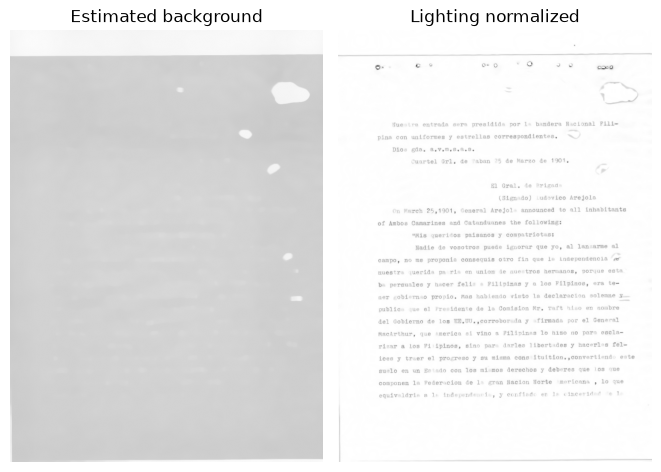

In [16]:
kernel = np.ones((7, 7), np.uint8)
background = cv2.dilate(denoised, kernel)
background = cv2.medianBlur(background, 21)
normalized = cv2.divide(denoised, background, scale=255)
show([background, normalized], ["Estimated background", "Lighting normalized"])

## Step 5. Improve contrast with CLAHE
CLAHE boosts contrast in small tiles, so faded ink becomes darker without blowing out the whole page.
`clipLimit` controls strength (try 1.0 to 4.0); `tileGridSize` is the tile layout.

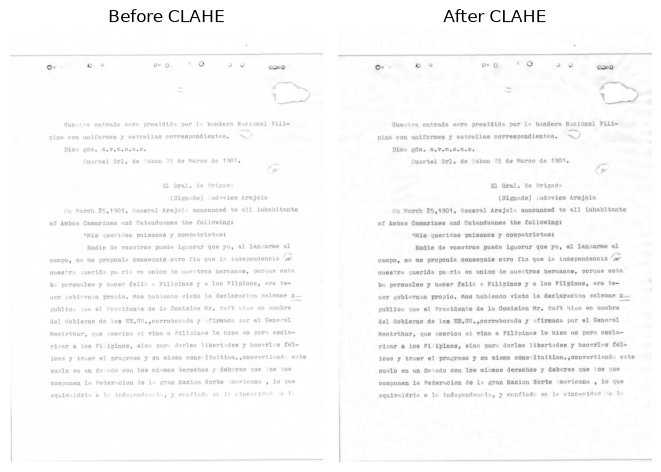

In [17]:
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
enhanced = clahe.apply(normalized)
show([normalized, enhanced], ["Before CLAHE", "After CLAHE"])

## Step 6. Deskew (straighten the page)
Scanned pages are often slightly tilted. We try small rotation angles and keep the one where text lines are
most distinct (highest variance of the row sums). This avoids the angle-convention problems of `minAreaRect`.

Estimated correction angle: -0.5 degrees


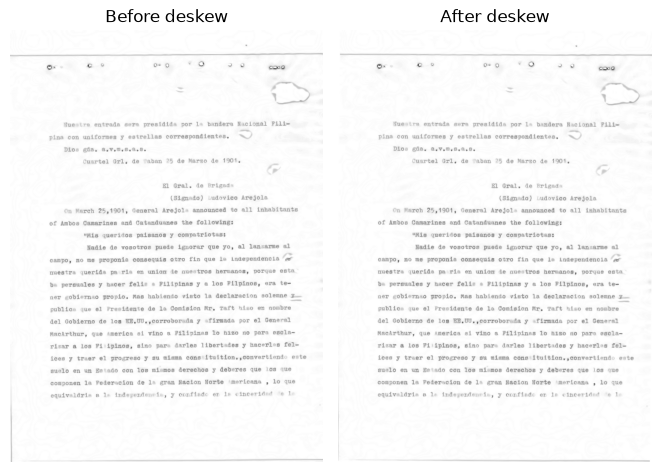

In [18]:
def estimate_skew(gray_img, max_angle=10, step=0.5):
    """Return the angle (degrees) that, when applied with rotate(), makes text lines horizontal."""
    scale = 800 / max(gray_img.shape)
    small = cv2.resize(gray_img, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA) if scale < 1 else gray_img
    _, bw = cv2.threshold(small, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    h, w = bw.shape
    center = (w // 2, h // 2)
    best_angle, best_score = 0.0, -1.0
    for angle in np.arange(-max_angle, max_angle + step, step):
        M = cv2.getRotationMatrix2D(center, angle, 1.0)
        rotated = cv2.warpAffine(bw, M, (w, h), flags=cv2.INTER_NEAREST, borderValue=0)
        score = np.var(rotated.sum(axis=1))
        if score > best_score:
            best_angle, best_score = angle, score
    return best_angle

def rotate(gray_img, angle):
    h, w = gray_img.shape
    M = cv2.getRotationMatrix2D((w // 2, h // 2), angle, 1.0)
    return cv2.warpAffine(gray_img, M, (w, h), flags=cv2.INTER_CUBIC,
                          borderMode=cv2.BORDER_CONSTANT, borderValue=255)

angle = estimate_skew(enhanced)
print(f"Estimated correction angle: {angle:.1f} degrees")
deskewed = rotate(enhanced, angle)
show([enhanced, deskewed], ["Before deskew", "After deskew"])

## Step 7. Thresholding (separate text from background)
This answers **RQ2**. We compare three methods and look at which gives the cleanest handwriting:

- **Global**: one fixed cutoff for the whole page (fast, fails with uneven ink).
- **Otsu**: picks the single best cutoff automatically.
- **Adaptive Gaussian**: a different cutoff for each small region (usually best for stained or uneven pages).

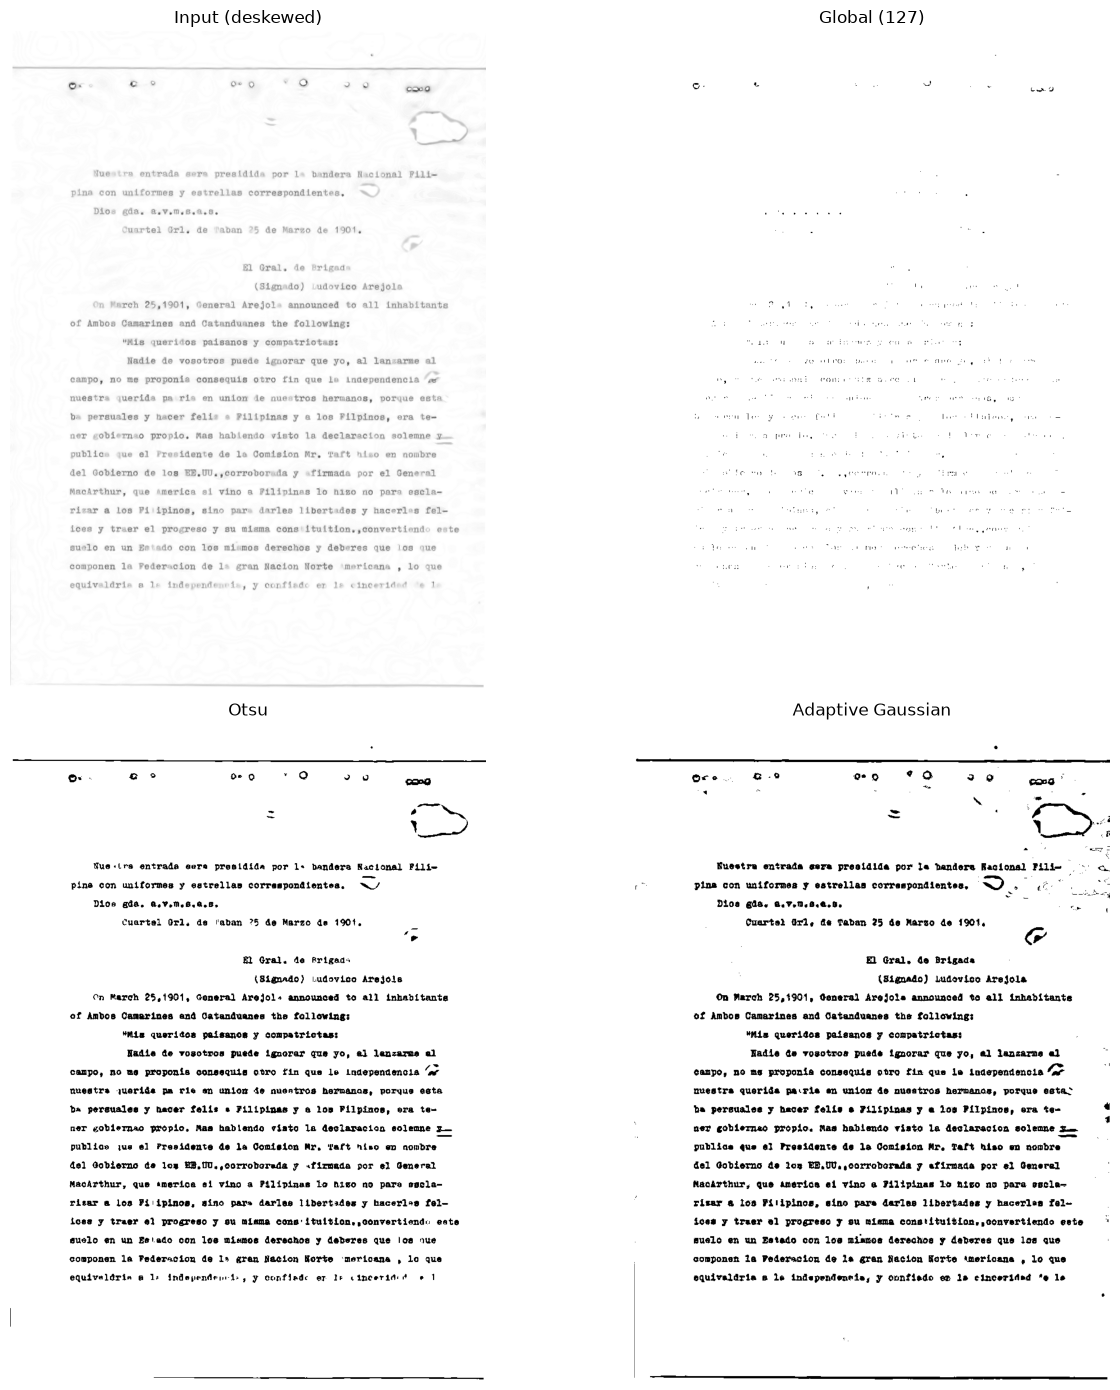

In [23]:
# Slightly smoother blur to catch faint ink uniformly
blur = cv2.GaussianBlur(deskewed, (1, 1), 0)

_, th_global = cv2.threshold(blur, 127, 255, cv2.THRESH_BINARY)
_, th_otsu = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# Lower C from 15 to 5 to prevent text from looking overly thick/bold
th_adaptive = cv2.adaptiveThreshold(blur, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                    cv2.THRESH_BINARY, blockSize=35, C=5)

show([deskewed, th_global, th_otsu, th_adaptive],
     ["Input (deskewed)", "Global (127)", "Otsu", "Adaptive Gaussian"], cols=2, size=7)

**Tuning tips:** for adaptive thresholding, `blockSize` must be odd (larger = smoother, try 25 to 51) and `C` is subtracted from the local mean (larger = less noise, but thin strokes may disappear).
Pick the method that keeps the handwriting complete with the least background noise, and record your choice for the paper.

## Step 8. Clean up small specks (optional)
Morphological opening removes tiny isolated dots. Text is black on white here, so we invert, clean, then invert back.

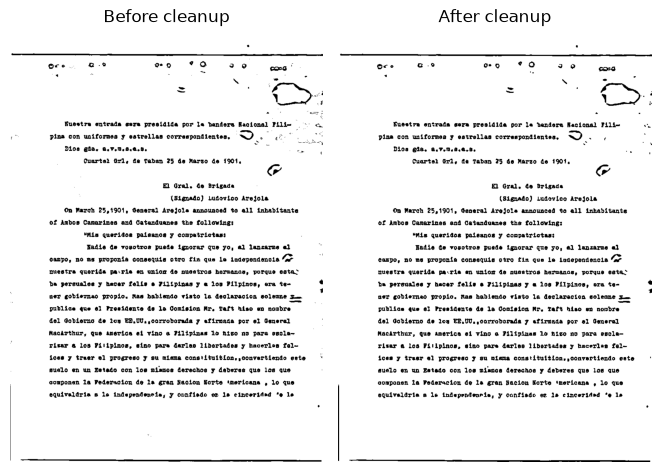

In [24]:
CHOSEN = th_adaptive   # change to th_otsu or th_global after comparing

inv = cv2.bitwise_not(CHOSEN)
inv = cv2.morphologyEx(inv, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))
final = cv2.bitwise_not(inv)
show([CHOSEN, final], ["Before cleanup", "After cleanup"])

## Step 9. Save the processed images
These files are your **preliminary processed images** for the submission, and the input for the OCR stage.

In [25]:
OUT_DIR = os.path.join(ROOT, "outputs", "processed_images")
os.makedirs(OUT_DIR, exist_ok=True)

steps = {
    "01_gray": gray,
    "02_denoised": denoised,
    "03_lighting_normalized": normalized,
    "04_clahe": enhanced,
    "05_deskewed": deskewed,
    "06a_threshold_global": th_global,
    "06b_threshold_otsu": th_otsu,
    "06c_threshold_adaptive": th_adaptive,
    "07_final": final,
}
for name, im in steps.items():
    cv2.imwrite(os.path.join(OUT_DIR, f"{name}.png"), im)
print("Saved", len(steps), "images to", OUT_DIR)

Saved 9 images to ../outputs/processed_images


## Step 10. Quick OCR check (optional)
A fast way to see whether preprocessing helped: run Tesseract on the original grayscale and on your final image and compare the text.
This needs `pytesseract` and the Tesseract program with Spanish data (`spa`) installed. Skip this step if you have not set it up yet.

In [26]:
try:
    import pytesseract
    cfg = "--psm 6"
    print("--- OCR on plain grayscale ---")
    print(pytesseract.image_to_string(gray, lang="spa", config=cfg)[:500])
    print("--- OCR on preprocessed image ---")
    print(pytesseract.image_to_string(final, lang="spa", config=cfg)[:500])
except Exception as e:
    print("OCR check skipped:", e)

--- OCR on plain grayscale ---
OCR check skipped: tesseract is not installed or it's not in your PATH. See README file for more information.


## Step 11. Summary figure for the paper

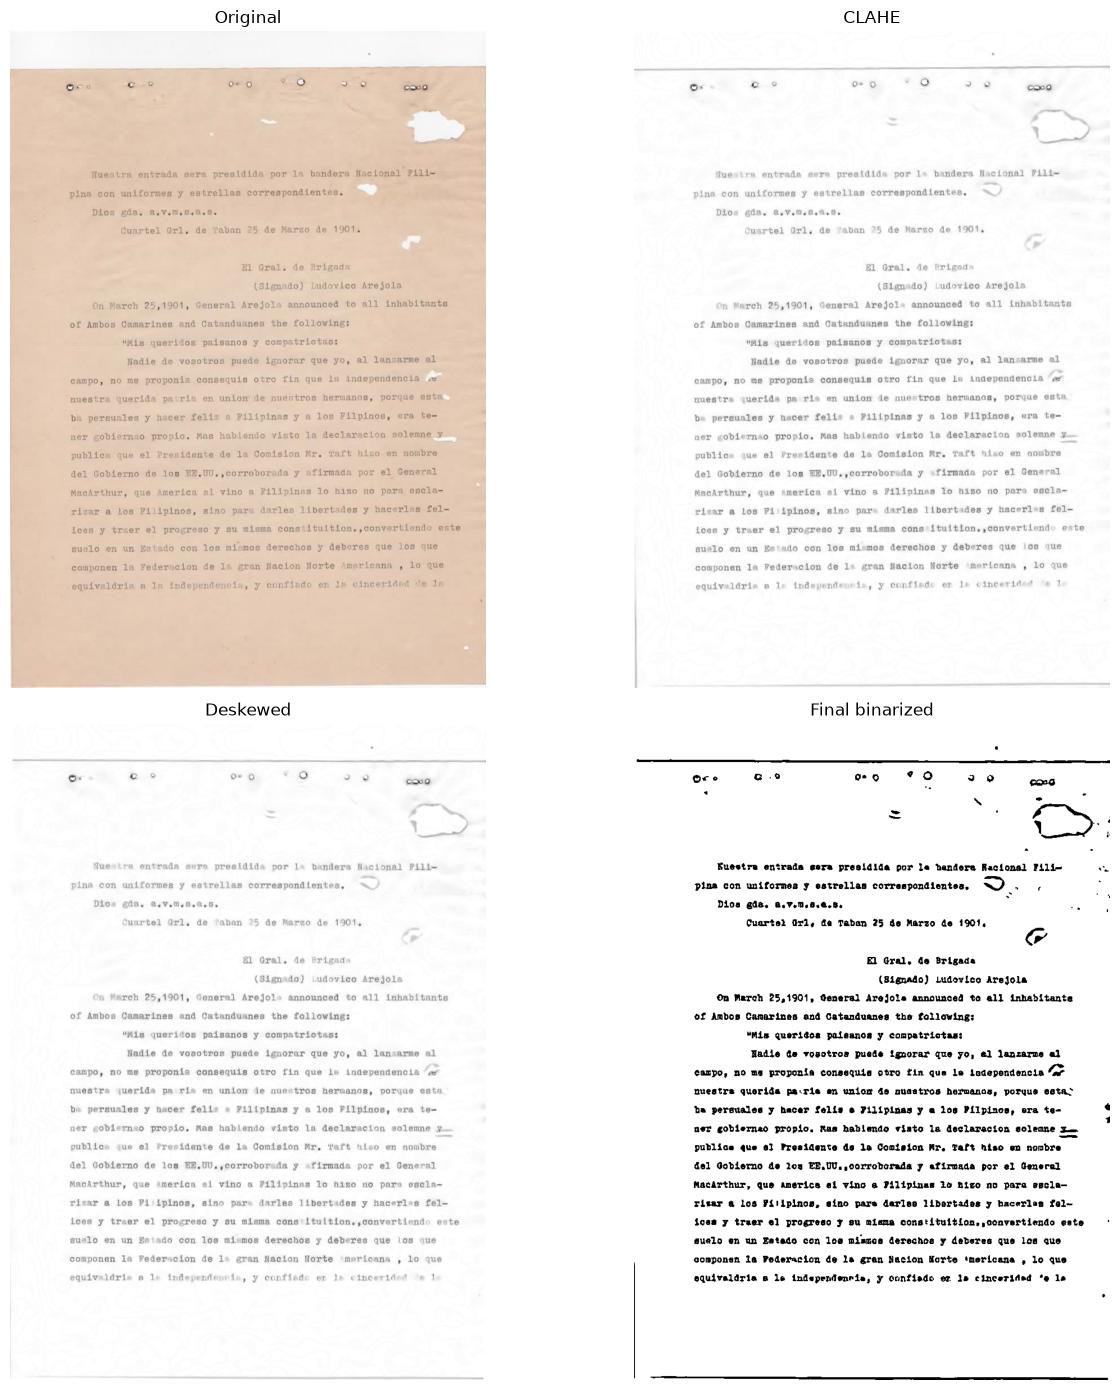

In [27]:
show([img, enhanced, deskewed, final],
     ["Original", "CLAHE", "Deskewed", "Final binarized"], cols=2, size=7)